# Clase 1 y 2 - Simulación de símbolos LoRa mediante chirps

En este notebook generamos símbolos LoRa a partir de la ecuación (3) del artículo de Vangelista y los recuperamos con *dechirp* y una FFT. En la etapa 6 construimos por separado una vista real a partir de la rampa de frecuencia solicitada, para comprobar cómo se relacionan frecuencia y señal temporal.

## Etapa 1 — Importar librerías y fijar parámetros

Usamos `numpy` para los cálculos numéricos y `matplotlib` para las gráficas. El ancho de banda se fija en 125 kHz.

In [7]:
import matplotlib.pyplot as plt
import numpy as np

B = 125_000  # ancho de banda [Hz]
SOBREMUESTREO_GRAFICO = 64  # sólo para evaluar la fase al dibujar

## Etapa 2 — Definir la trama y validar la entrada

Cada símbolo se escribe como una cadena binaria. Su cantidad de bits determina el *spreading factor* (`SF`). Por ejemplo, `00100101` tiene 8 bits, así que `SF = 8` y hay $N = 2^{SF} = 256$ valores de símbolo posibles.

La función siguiente verifica que todos los símbolos tengan la misma longitud y solo contengan ceros y unos.

In [8]:
simbolos = ["00100101", "11110000", "00000011"]

def validar_simbolos(simbolos):
    if not isinstance(simbolos, (list, tuple)):
        raise TypeError("simbolos debe ser una lista o tupla de cadenas binarias")
    if not all(isinstance(bits, str) and set(bits) <= {"0", "1"} for bits in simbolos):
        raise ValueError("cada simbolo debe ser una cadena formada solo por '0' y '1'")

    sf = len(simbolos[0])
    if sf == 0 or any(len(bits) != sf for bits in simbolos):
        raise ValueError("todos los simbolos deben tener la misma longitud y al menos un bit")
    return sf

sf = validar_simbolos(simbolos)
N = 2**sf
Ts = N / B
print(f"SF={sf}, N={N}, duración de símbolo Ts={Ts * 1e3:.3f} ms")


SF=8, N=256, duración de símbolo Ts=2.048 ms


## Etapa 3 — Construir las muestras del chirp

El artículo define el chirp sólo en tiempo discreto, para $k=0,\ldots,N-1$:

$$T=\frac{1}{B},\qquad N=2^{SF},\qquad T_s=\frac{N}{B},\qquad c_s[k]=\frac{1}{\sqrt N}\exp\!\left(j2\pi\frac{[(s+k)\bmod N]k}{N}\right).$$

La celda siguiente conserva exactamente la ecuación del chirp. El vector que recibe el demodulador tiene `N` muestras. En la etapa 6 se desarrolla por separado la fase que evaluaremos con más puntos para dibujar.

In [9]:
def modular_simbolo(valor, k, N):
    """Implementa la ecuación del chirp para k=0,...,N-1."""
    fase_discreta = ((valor + k) % N) * k / N
    chirp = np.exp(1j * 2 * np.pi * fase_discreta) / np.sqrt(N)
    tiempo = k / B
    indice_ecuacion = np.mod(valor + k, N) * B / N
    return chirp, tiempo, chirp.real, chirp.imag, indice_ecuacion


## Etapa 4 — Modular y construir la señal recibida

Primero convertimos cada cadena binaria a su valor decimal y modulamos cada una. En esta primera prueba ideal, la señal recibida es exactamente el chirp transmitido; más adelante se podrá reemplazar por una señal con ruido.

In [10]:
k = np.arange(N)

# Conversion de binarios a enteros
valores_enviados = [int(bits, 2) for bits in simbolos]

recibidas = []
vistas = []

# Modulacion de los simbolosy recepcion ideal
for valor in valores_enviados:
    chirp, tiempo, real, imaginaria, frecuencia = modular_simbolo(valor, k, N)
    recibidas.append(chirp)  # Canal ideal: r[k] = c[k].
    vistas.append((tiempo, real, imaginaria, frecuencia))

print(f"Se construyeron {len(recibidas)} señales recibidas ideales.")


Se construyeron 3 señales recibidas ideales.


## Etapa 5 — Demodular con down-chirp y FFT

El receptor recibe $r[k]$. En un canal ideal, $r[k]=c_s[k]$; con ruido, sería $r[k]=c_s[k]+w[k]$. Multiplicar muestra a muestra por el *down-chirp* $e^{-j2\pi k^2/N}$ cancela el término cuadrático del chirp. Lo que queda es un tono complejo $e^{j2\pi sk/N}$, cuya FFT concentra toda la energía en el bin $s$.

Por eso el símbolo estimado es el índice de mayor energía: `argmax(abs(FFT)**2)`.

In [11]:
def demodular_simbolo(recibida):
    """Devuelve el símbolo estimado, la señal dechirpeada y su FFT."""

    recibida = np.asarray(recibida, dtype=complex)
    N_recibido = len(recibida)
    k_recibido = np.arange(N_recibido)

    if N_recibido == 0:
        raise ValueError("la señal recibida no puede estar vacía")

    downchirp = np.exp(-1j * 2 * np.pi * k_recibido**2 / N_recibido)
    dechirpeada = recibida * downchirp
    espectro = np.fft.fft(dechirpeada)
    simbolo_estimado = int(np.argmax(np.abs(espectro)**2))
    return simbolo_estimado, dechirpeada, espectro

valores_estimados = [demodular_simbolo(r)[0] for r in recibidas]
assert valores_estimados == valores_enviados

for bits, enviado, estimado in zip(simbolos, valores_enviados, valores_estimados):
    print(f"{bits} → s={enviado}; detectado={estimado}")


00100101 → s=37; detectado=37
11110000 → s=240; detectado=240
00000011 → s=3; detectado=3


## Etapa 6 — Señal real y su frecuencia

Arriba dibujamos una señal **real**; abajo, la frecuencia que se usa para construirla. Cuando esa frecuencia vuelve a cero, la señal pasa de ciclos rápidos a ciclos lentos y conserva la continuidad de su fase.

Se definen:

$$T_s=\frac{N}{B},\qquad f_0=\frac{sB}{N},\qquad a=\frac{B}{T_s},\qquad t_r=\frac{B-f_0}{a}=\frac{N-s}{B}.$$

$$f(t)=
\begin{cases}
f_0+at, & 0\le t<t_r,\\
f_0+at-B, & t_r\le t<T_s.
\end{cases}$$

La fase se obtiene **integrando esa misma frecuencia**, y la señal real es su coseno:

$$\phi(t)=2\pi\int_0^t f(\tau)\,d\tau
=2\pi\left[f_0t+\frac{a}{2}t^2-B\max(0,t-t_r)\right],
\qquad x(t)=\frac{1}{\sqrt N}\cos\phi(t).$$

Evaluamos estas fórmulas con 64 puntos por intervalo de muestra. Para el ejemplo $s=37$, $N=256$, $B=125000$ el reinicio ocurre en  $t_r=219/125000=1{,}752\ \mathrm{ms}$. Las dos gráficas comparten el eje temporal y marcan ese instante con la misma línea vertical.

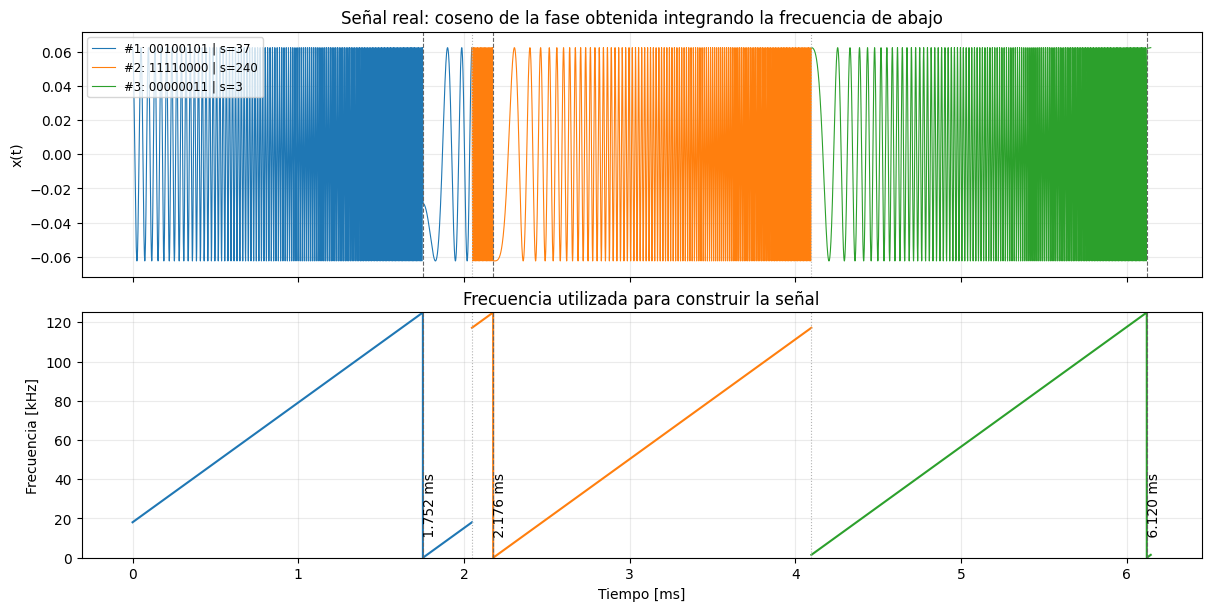

In [12]:
L = SOBREMUESTREO_GRAFICO
u = np.arange(N * L) / L
tiempo_local = u / B
amplitud = 1 / np.sqrt(N)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)

# Definimos la rampa de frecuencia
for indice, (bits, enviado) in enumerate(zip(simbolos, valores_enviados)):
    f_inicial = enviado * B / N
    pendiente = B / Ts
    tiempo_reinicio = (N - enviado) / B

    frecuencia = np.mod(enviado + u, N) * B / N
    fase = 2 * np.pi * (
        f_inicial * tiempo_local
        + pendiente * tiempo_local**2 / 2
        - B * np.maximum(0, tiempo_local - tiempo_reinicio)
    )
    senal_real = amplitud * np.cos(fase)

    # Graficamos la parte real de la señal y la frecuencia
    tiempo_ms = (indice * Ts + tiempo_local) * 1e3
    etiqueta = f"#{indice + 1}: {bits} | s={enviado}"
    linea, = axes[0].plot(tiempo_ms, senal_real, lw=0.8, label=etiqueta)
    axes[1].plot(tiempo_ms, frecuencia / 1e3, color=linea.get_color())

    if enviado > 0:
        reinicio_ms = (indice * Ts + tiempo_reinicio) * 1e3
        for ax in axes:
            ax.axvline(reinicio_ms, color="0.4", ls="--", lw=0.8)
        axes[1].text(reinicio_ms, B / 1e3 * 0.08, f" {reinicio_ms:.3f} ms", rotation=90)

for limite_ms in np.arange(1, len(simbolos)) * Ts * 1e3:
    for ax in axes:
        ax.axvline(limite_ms, color="0.7", ls=":", lw=0.8)

axes[0].set(title="Señal real: coseno de la fase obtenida integrando la frecuencia de abajo",
            ylabel="x(t)", ylim=(-1.15 * amplitud, 1.15 * amplitud))
axes[1].set(title="Frecuencia utilizada para construir la señal",
            xlabel="Tiempo [ms]", ylabel="Frecuencia [kHz]", ylim=(0, B / 1e3))
for ax in axes:
    ax.grid(True, alpha=0.25)
axes[0].legend(fontsize="small", loc="upper left")
plt.show()


## BER: proporción de bits errados

Comparamos los bits enviados y recibidos, en el mismo orden:

$$P_e=\mathrm{BER}_{\mathrm{medido}}=\frac{\text{bits errados}}{\text{bits totales}}.$$

Un BER de 0 significa que no hubo errores en los bits observados; no demuestra por sí solo que la probabilidad teórica de error sea cero.

In [13]:
def calc_error(bits_enviados, bits_recibidos):
    """Devuelve el BER: bits distintos dividido por bits enviados."""
    
    bits_errados = sum(
        bit_enviado != bit_recibido
        for bit_enviado, bit_recibido in zip(bits_enviados, bits_recibidos)
    )
    return bits_errados / len(bits_enviados)

## Etapa 7 — Pico que recupera el símbolo

Cada fila es la energía de la FFT después de multiplicar la señal recibida por el *down-chirp*. En el caso ideal, toda la energía queda concentrada en el bin del símbolo transmitido.

37  en binario es  00100101  el que se mandó fue  00100101
Probabilidad de error (BER) 0.0
240  en binario es  11110000  el que se mandó fue  11110000
Probabilidad de error (BER) 0.0
3  en binario es  00000011  el que se mandó fue  00000011
Probabilidad de error (BER) 0.0


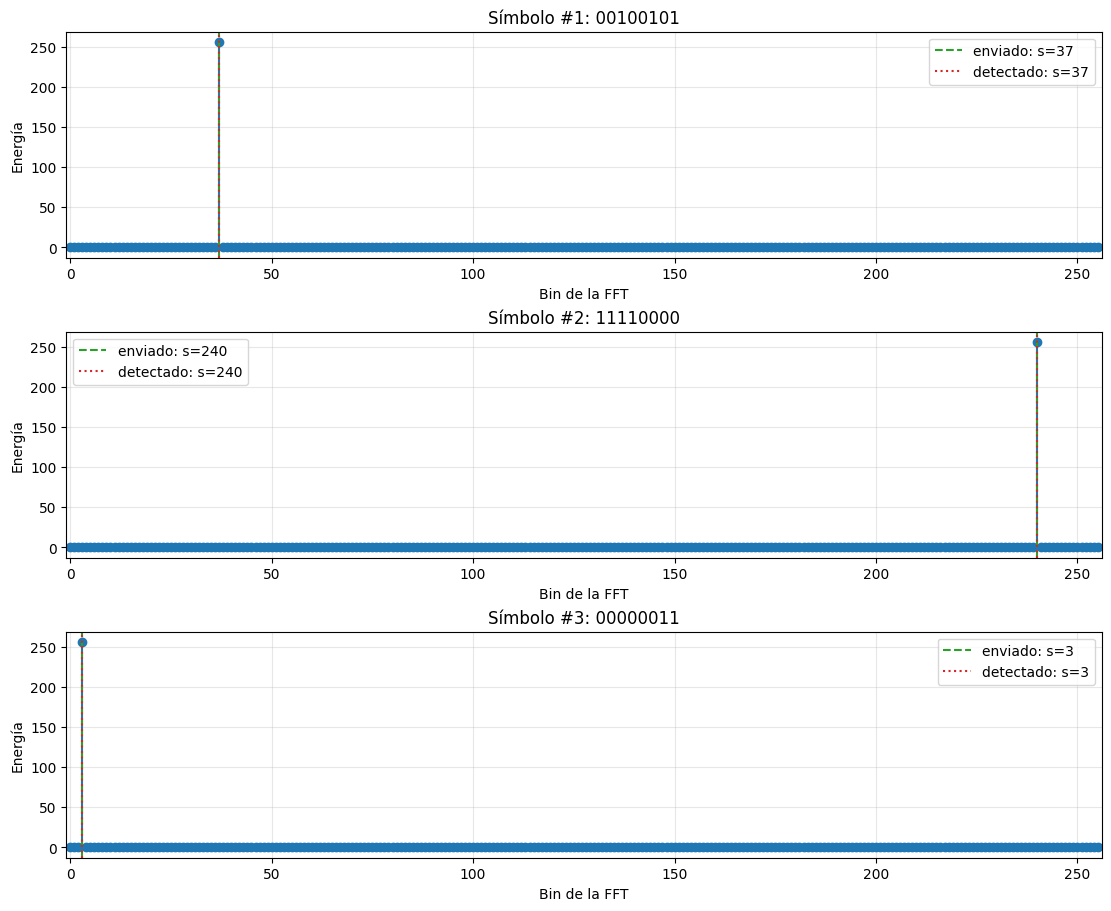

In [14]:
resultados = [demodular_simbolo(recibida) for recibida in recibidas]

fig, axes = plt.subplots(len(resultados), 1, figsize=(11, 3 * len(resultados)), squeeze=False, constrained_layout=True)


for indice, ((estimado, _, espectro), bits, enviado) in enumerate(
    zip(resultados, simbolos, valores_enviados)
):
    energia = np.abs(espectro)**2
    ax = axes[indice, 0]
    ax.stem(np.arange(N), energia, basefmt=" ")
    ax.axvline(enviado, color="tab:green", linestyle="--", label=f"enviado: s={enviado}")
    ax.axvline(estimado, color="tab:red", linestyle=":", label=f"detectado: s={estimado}")
    ax.set(title=f"Símbolo #{indice + 1}: {bits}", xlabel="Bin de la FFT", ylabel="Energía")
    ax.set_xlim(-1, N)
    ax.grid(True, alpha=0.3)
    ax.legend()

    print(estimado, " en binario es ", format(estimado, f"0{sf}b"), " el que se mandó fue ", format(enviado, f"0{sf}b"))
    bits_detectados = format(estimado, f"0{sf}b")
    print("Probabilidad de error (BER)", calc_error(format(enviado, f"0{sf}b"), bits_detectados))

plt.show()


## Potencia de la señal recibida

La potencia promedio se obtiene promediando $|r[k]|^2$. La suma de esos valores es la energía discreta total del símbolo.

In [19]:
def calcular_potencia(senal):
    """Devuelve la potencia promedio de las muestras reales o complejas de una senal."""
    senal = np.asarray(senal)
    if senal.size == 0:
        raise ValueError("La senal debe contener al menos una muestra.")
    return np.mean(np.abs(senal)**2)


for indice, recibida in enumerate(recibidas, start=1):
    potencia_promedio = calcular_potencia(recibida)
    energia_total = np.sum(np.abs(recibida)**2)
    print(
        f"Símbolo #{indice}: potencia promedio = {potencia_promedio:.6f}; "
        f"energía total = {energia_total:.6f}"
    )


Símbolo #1: potencia promedio = 0.003906; energía total = 1.000000
Símbolo #2: potencia promedio = 0.003906; energía total = 1.000000
Símbolo #3: potencia promedio = 0.003906; energía total = 1.000000


## Se añade ruido gaussiano complejo y se mide su potencia 

La señal recibida ahora es la señal enviada más ruido:

$$r[k]=c[k]+w[k],\qquad E\{w[k]\}=0,\qquad E\{|w[k]|^2\}=\sigma^2.$$
El ruido agregado es gaussiano $w\sim\mathcal{CN}(0,\sigma^2 I)$. La potencia teórica de cada muestra de ruido es $\sigma^2$.

`standard_normal` genera muestras gaussianas reales con media cero y varianza uno. Usamos dos vectores independientes, $z_I[k]$ y $z_Q[k]$, para construir las partes real e imaginaria:

$$
w[k]=\frac{\sigma}{\sqrt{2}}\left(z_I[k]+jz_Q[k]\right).
$$

El factor $j$ coloca el segundo vector en la parte imaginaria. Al multiplicar cada componente por $\sigma/\sqrt{2}$, su varianza pasa a ser $\sigma^2/2$. Como el módulo al cuadrado de un complejo es la suma de los cuadrados de sus componentes, la potencia total resulta:

$$
\mathbb{E}\{|w[k]|^2\}
=\mathbb{E}\{(\operatorname{Re}w[k])^2\}
+\mathbb{E}\{(\operatorname{Im}w[k])^2\}
=\frac{\sigma^2}{2}+\frac{\sigma^2}{2}
=\sigma^2.
$$

In [20]:
sigma = 0.02  # Desvío estándar complejo: potencia teórica del ruido = sigma**2.
generador = np.random.default_rng(2026)  # Semilla fija: permite repetir el ejemplo.

senal_transmitida = recibidas[0]
cantidad_muestras = len(senal_transmitida)
ruido = sigma / np.sqrt(2) * (
    generador.standard_normal(cantidad_muestras)
    + 1j * generador.standard_normal(cantidad_muestras)
)
senal_ruidosa = senal_transmitida + ruido

potencia_senal = calcular_potencia(senal_transmitida)
potencia_ruido_medida = calcular_potencia(ruido)
potencia_recibida = calcular_potencia(senal_ruidosa)
snr_teorica_db = 10 * np.log10(potencia_senal / sigma**2)
snr_medida_db = 10 * np.log10(potencia_senal / potencia_ruido_medida)

print(f"Potencia de la señal:       {potencia_senal:.6f}")
print(f"Potencia teórica del ruido: {sigma**2:.6f}")
print(f"Potencia medida del ruido:  {potencia_ruido_medida:.6f}")
print(f"Potencia de señal ruidosa:  {potencia_recibida:.6f}")
print(f"SNR teórica: {snr_teorica_db:.2f} dB")
print(f"SNR medida:  {snr_medida_db:.2f} dB")


Potencia de la señal:       0.003906
Potencia teórica del ruido: 0.000400
Potencia medida del ruido:  0.000448
Potencia de señal ruidosa:  0.004315
SNR teórica: 9.90 dB
SNR medida:  9.40 dB


## Obtener los parámetros del ruido a partir de SNR

La función recibe una SNR objetivo en dB y usa la potencia de la señal calculada antes. A partir de $$\mathrm{SNR}_{dB}=10\log_{10}(P_s/P_n)$$ despeja $P_n$ y luego calcula $\sigma=\sqrt{P_n}$.

In [21]:
def parametros_ruido_desde_snr(snr_db):
    """Devuelve potencia de ruido y sigma para la SNR objetivo en dB."""
    if not np.isfinite(snr_db):
        raise ValueError("snr_db debe ser un número finito")

    snr_lineal = 10**(snr_db / 10)
    potencia_ruido = potencia_senal / snr_lineal
    sigma = np.sqrt(potencia_ruido)
    return potencia_ruido, sigma

snr_objetivo_db = 10
potencia_ruido_objetivo, sigma_objetivo = parametros_ruido_desde_snr(snr_objetivo_db)

print(f"SNR objetivo: {snr_objetivo_db:.2f} dB")
print(f"Potencia de ruido necesaria: {potencia_ruido_objetivo:.6f}")
print(f"Sigma (desviacion estandar): {sigma_objetivo:.6f}")


SNR objetivo: 10.00 dB
Potencia de ruido necesaria: 0.000391
Sigma (desviacion estandar): 0.019764
